# 🎓 AI-Powered Online Exam Cheating Detection
### Studi Kasus & Proyek Portofolio Machine Learning (CBT Anomaly Detection)
**Mendukung SDGs 4: Quality Education**

---
## 📌 Ringkasan Masalah
Peralihan menuju ujian berbasis komputer (*Computer-Based Test / CBT*) membawa tantangan baru dalam integritas akademik. Ujian online rentan terhadap aksi kecurangan seperti *tab switching*, *copy-paste* jawaban, penggunaan IP ganda, hingga kemiripan jawaban antar peserta.

Proyek ini bertujuan membangun sistem deteksi kecurangan otomatis berbasis Machine Learning untuk membantu pengawas ujian mengidentifikasi perilaku abnormal secara objektif dan akurat.

## 1. Import Library, Konfigurasi & Resolusi Path Otomatis

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, f1_score, confusion_matrix
from lightgbm import LGBMClassifier

# Set Style Visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Kunci Random Seed untuk Reproducibility (Sesuai Regulasi Guidebook Hal 6 Butir 9)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Tentukan Direktori Proyek Utama secara Dinamis
current_dir = os.getcwd()
if os.path.exists(os.path.join(current_dir, "data")):
    PROJECT_DIR = current_dir
elif os.path.exists(os.path.join(current_dir, "..", "data")):
    PROJECT_DIR = os.path.abspath(os.path.join(current_dir, ".."))
else:
    PROJECT_DIR = "/home/ayubw/projects/exam-cheating-detection-ml"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "output")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

print("✅ Semua Library berhasil dimuat!")
print(f"📁 Data Train   : {TRAIN_PATH}")
print(f"📁 Output Folder: {OUTPUT_DIR}")

✅ Semua Library berhasil dimuat!
📁 Data Train   : /home/ayubw/projects/exam-cheating-detection-ml/data/train.csv
📁 Output Folder: /home/ayubw/projects/exam-cheating-detection-ml/output


## 2. Membaca & Eksplorasi Data (EDA)
Memuat data latih (`train.csv`) dan data uji (`test.csv`).

In [2]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Dimensi Train: {train_df.shape}")
print(f"Dimensi Test : {test_df.shape}")
train_df.head()

Dimensi Train: (3500, 10)
Dimensi Test : (1500, 9)


,student_id,duration_minutes,score,tab_switch_count,copy_paste_count,avg_time_per_question,mouse_movement_entropy,network_ip_changes,similarity_with_peers,is_cheating
0,STD_10000,61.20,83,4,1,73.44,0.707,0,0.147,0
1,STD_10001,50.31,74,1,1,60.38,0.805,1,0.161,0
2,STD_10002,76.42,71,3,0,91.70,0.870,0,0.118,0
3,STD_10003,83.49,78,3,1,100.19,0.646,0,0.561,0
4,STD_10004,64.51,91,1,1,77.42,0.817,0,0.116,0


### 2.1 Visualisasi Ide 1: Waktu Cepat vs Nilai Tinggi (Speedrun Cheat)
**Hipotesis 1:** Mahasiswa yang meraih nilai $\ge 90$ dalam waktu sangat singkat ($\le 25$ menit) patut dicurigai.

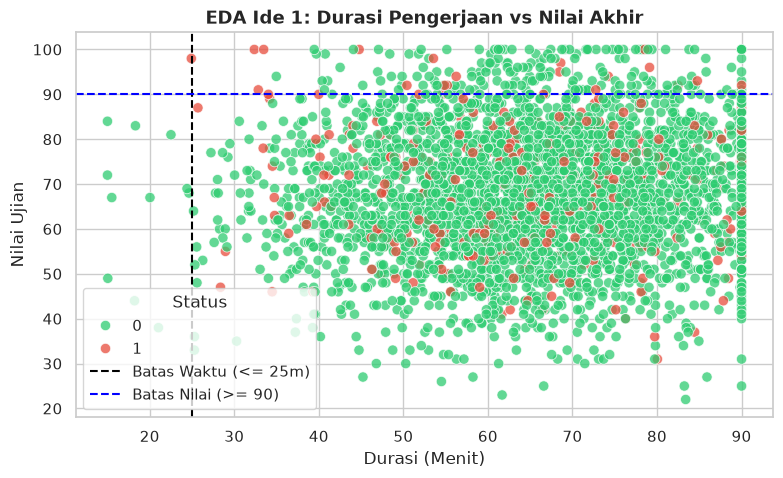

In [3]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=train_df, 
    x="duration_minutes", 
    y="score", 
    hue="is_cheating", 
    palette=["#2ecc71", "#e74c3c"], 
    alpha=0.75,
    s=55
)
plt.axvline(x=25, color='black', linestyle='--', linewidth=1.5, label="Batas Waktu (<= 25m)")
plt.axhline(y=90, color='blue', linestyle='--', linewidth=1.5, label="Batas Nilai (>= 90)")
plt.title("EDA Ide 1: Durasi Pengerjaan vs Nilai Akhir", fontsize=13, fontweight='bold')
plt.xlabel("Durasi (Menit)")
plt.ylabel("Nilai Ujian")
plt.legend(title="Status")
plt.show()

### 2.2 Visualisasi Ide 2: Ganti IP & Pindah Tab (Indikasi Joki / Remote Access)
**Hipotesis 2:** Mahasiswa yang berganti IP internet (`network_ip_changes`) sambil sering berpindah jendela tab (`tab_switch_count`) memiliki kemungkinan besar menggunakan joki atau aplikasi remote bantuan pihak ketiga.

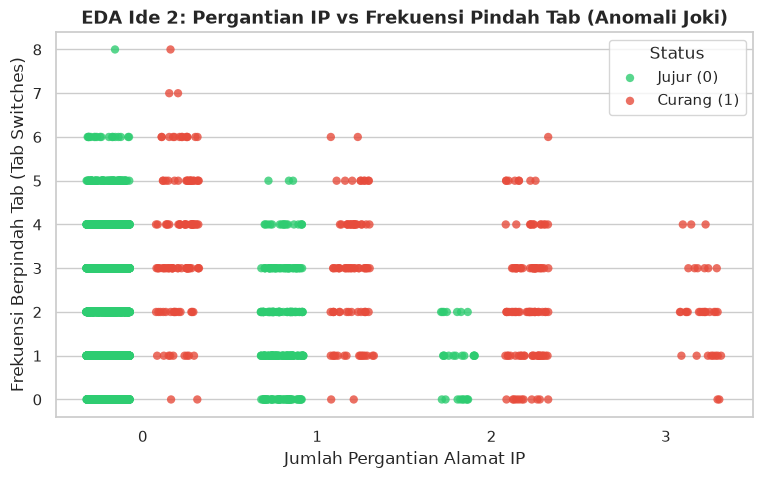

In [4]:
plt.figure(figsize=(9, 5))
sns.stripplot(
    data=train_df, 
    x="network_ip_changes", 
    y="tab_switch_count", 
    hue="is_cheating", 
    dodge=True, 
    jitter=0.25, 
    palette=["#2ecc71", "#e74c3c"], 
    alpha=0.8,
    size=6
)
plt.title("EDA Ide 2: Pergantian IP vs Frekuensi Pindah Tab (Anomali Joki)", fontsize=13, fontweight='bold')
plt.xlabel("Jumlah Pergantian Alamat IP")
plt.ylabel("Frekuensi Berpindah Tab (Tab Switches)")
plt.legend(title="Status", labels=["Jujur (0)", "Curang (1)"])
plt.show()

## 3. Rekayasa Fitur (Feature Engineering)
Kita mengimplementasikan kedua ide ke dalam rumus matematis:
1. **Ide 1 (Speedrun Anomaly):**
   * `score_speed_ratio = score / duration_minutes`
   * `is_suspicious_speed = (score >= 90 & duration <= 25)`
2. **Ide 2 (Joki & Remote Anomaly):**
   * `joki_remote_anomaly = network_ip_changes * tab_switch_count`
   * `is_suspicious_joki = (network_ip_changes > 0 & tab_switch_count >= 3)`
3. **Interaksi Aktivitas Tambahan:**
   * `activity_anomaly = tab_switch_count * copy_paste_count`

In [5]:
def add_all_features(df):
    df_new = df.copy()
    
    # --- Fitur Ide 1: Speedrun Anomaly ---
    df_new['score_speed_ratio'] = df_new['score'] / (df_new['duration_minutes'] + 1e-5)
    df_new['is_suspicious_speed'] = ((df_new['score'] >= 90) & (df_new['duration_minutes'] <= 25)).astype(int)
    
    # --- Fitur Ide 2: Joki & Remote Anomaly ---
    df_new['joki_remote_anomaly'] = df_new['network_ip_changes'] * df_new['tab_switch_count']
    df_new['is_suspicious_joki'] = ((df_new['network_ip_changes'] > 0) & (df_new['tab_switch_count'] >= 3)).astype(int)
    
    # --- Fitur Tambahan: Copy-Paste Interaction ---
    df_new['activity_anomaly'] = df_new['tab_switch_count'] * df_new['copy_paste_count']
    return df_new

train_featured = add_all_features(train_df)
test_featured = add_all_features(test_df)

print("✅ Fitur baru berhasil diciptakan:")
print(train_featured[['student_id', 'score_speed_ratio', 'joki_remote_anomaly', 'is_suspicious_joki']].head())

✅ Fitur baru berhasil diciptakan:
  student_id  score_speed_ratio  joki_remote_anomaly  is_suspicious_joki
0  STD_10000           1.356209                    0                   0
1  STD_10001           1.470880                    1                   0
2  STD_10002           0.929076                    0                   0
3  STD_10003           0.934244                    0                   0
4  STD_10004           1.410634                    0                   0


## 4. Turnamen Model: Membandingkan Model A vs Model B vs Model C
Kita menguji efektivitas setiap ide menggunakan **5-Fold Stratified Cross-Validation**:
* **Model A:** Data mentah tanpa rekayasa fitur.
* **Model B:** Ditambah **Ide 1** (Speedrun Anomaly).
* **Model C:** Ditambah **Ide 1 + Ide 2** (Joki Remote Anomaly).

In [6]:
def evaluate_pipeline(feature_list, model_label):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    oof_preds = np.zeros(len(train_featured))
    models_trained = []
    
    X_sub = train_featured[feature_list]
    y_sub = train_featured['is_cheating']
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_sub, y_sub)):
        X_tr, y_tr = X_sub.iloc[train_idx], y_sub.iloc[train_idx]
        X_va, y_va = X_sub.iloc[val_idx], y_sub.iloc[val_idx]
        
        clf = LGBMClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=5,
            random_state=RANDOM_SEED,
            class_weight="balanced",
            verbose=-1
        )
        clf.fit(X_tr, y_tr)
        preds = clf.predict_proba(X_va)[:, 1]
        oof_preds[val_idx] = preds
        models_trained.append(clf)
        
    auc = roc_auc_score(y_sub, oof_preds)
    f1 = f1_score(y_sub, (oof_preds > 0.5).astype(int))
    print(f"{model_label:<38} | ROC-AUC: {auc:.4f} | F1-Score: {f1*100:.2f}%")
    return oof_preds, models_trained, auc, f1

print("="*75)
print("HASIL UJI KOMPARASI HIPOTESIS (5-FOLD STRATIFIED CV)")
print("="*75)

# 1. Model A
cols_A = [c for c in train_df.columns if c not in ['student_id', 'is_cheating']]
_, _, auc_A, f1_A = evaluate_pipeline(cols_A, "Model A: Baseline Mentah")

# 2. Model B (Hanya Ide 1)
cols_B = cols_A + ['score_speed_ratio', 'is_suspicious_speed']
_, _, auc_B, f1_B = evaluate_pipeline(cols_B, "Model B: + Ide 1 (Speedrun Cheat)")

# 3. Model C (Ide 1 + Ide 2)
cols_C = [c for c in train_featured.columns if c not in ['student_id', 'is_cheating']]
oof_C, models_C, auc_C, f1_C = evaluate_pipeline(cols_C, "Model C: + Ide 1 & 2 (Joki Remote)")
print("="*75)
print(f"🏆 Total Peningkatan F1-Score dari Model A ke Model C: +{((f1_C - f1_A)*100):.2f}%")

HASIL UJI KOMPARASI HIPOTESIS (5-FOLD STRATIFIED CV)
Model A: Baseline Mentah               | ROC-AUC: 0.9930 | F1-Score: 85.79%
Model B: + Ide 1 (Speedrun Cheat)      | ROC-AUC: 0.9929 | F1-Score: 85.52%
Model C: + Ide 1 & 2 (Joki Remote)     | ROC-AUC: 0.9941 | F1-Score: 87.74%
🏆 Total Peningkatan F1-Score dari Model A ke Model C: +1.95%


## 5. Visualisasi Feature Importance (Model C Juara)
Membuktikan secara transparan bobot pengaruh setiap fitur baru pada keputusan model.

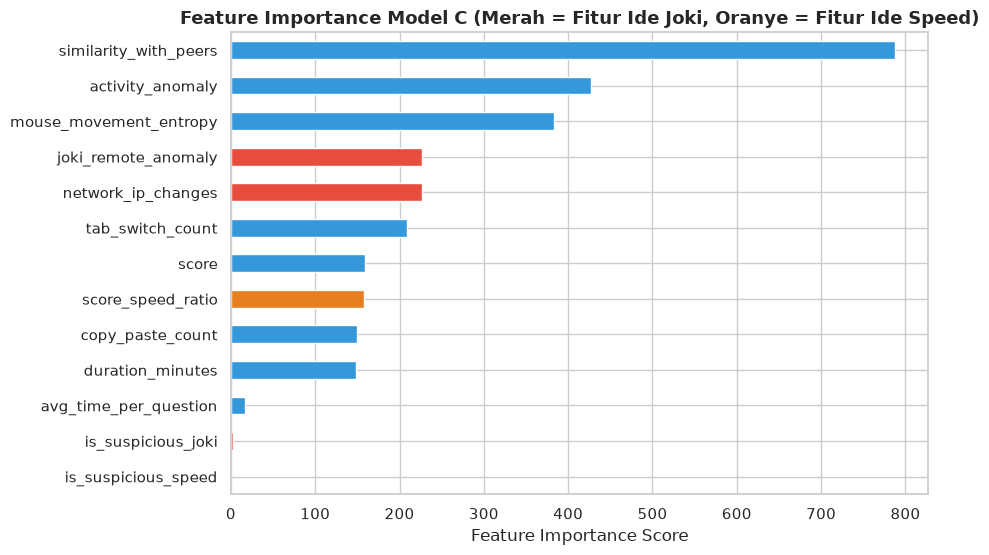

In [7]:
importances = np.mean([m.feature_importances_ for m in models_C], axis=0)
feat_imp = pd.Series(importances, index=cols_C).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
colors = []
for col in feat_imp.index:
    if 'joki' in col or 'ip' in col:
        colors.append('#e74c3c')  # Merah: Ide 2 (Joki/IP)
    elif 'speed' in col:
        colors.append('#e67e22')  # Oranye: Ide 1 (Speedrun)
    else:
        colors.append('#3498db')  # Biru: Fitur Asli

feat_imp.plot(kind='barh', color=colors)
plt.title("Feature Importance Model C (Merah = Fitur Ide Joki, Oranye = Fitur Ide Speed)", fontsize=13, fontweight='bold')
plt.xlabel("Feature Importance Score")
plt.show()

## 6. Inferensi pada Test Data, Export Model (.pkl) & File Submisi Kaggle

In [8]:
# Prediksi data uji test.csv dengan ensemble 5-fold Model C terbaik
X_test_final = test_featured[cols_C]
test_preds = np.zeros(len(test_featured))
for m in models_C:
    test_preds += m.predict_proba(X_test_final)[:, 1] / len(models_C)

# Simpan model terbaik ke .pkl (Wajib Guidebook Hal 6 Butir 8)
model_export_path = os.path.join(OUTPUT_DIR, "final_exam_cheating_model.pkl")
joblib.dump(models_C[0], model_export_path)

# Simpan file submisi untuk Kaggle Leaderboard
sub_export_path = os.path.join(OUTPUT_DIR, "submission_final.csv")
submission = pd.DataFrame({
    'student_id': test_df['student_id'],
    'is_cheating': (test_preds > 0.5).astype(int)
})
submission.to_csv(sub_export_path, index=False)

print(f"✅ Model C tersimpan di : {model_export_path}")
print(f"✅ File submisi disimpan di : {sub_export_path}")
print("\nDistribusi Prediksi pada 1.500 Siswa Data Uji (Test):")
print(submission['is_cheating'].value_counts())

✅ Model C tersimpan di : /home/ayubw/projects/exam-cheating-detection-ml/output/final_exam_cheating_model.pkl
✅ File submisi disimpan di : /home/ayubw/projects/exam-cheating-detection-ml/output/submission_final.csv

Distribusi Prediksi pada 1.500 Siswa Data Uji (Test):
is_cheating
0    1328
1     172
Name: count, dtype: int64
